[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/nattaponm/Teach_RQI_Mosaic_SpatialBias_DualPol/blob/main/notebooks/07_verification_interpretation.ipynb)

# 07 · การตรวจสอบความถูกต้องของฝนเรดาร์และการแปลผล
*Verifying radar rainfall against gauges and interpreting the results*

| | |
|---|---|
| **ระดับ** | 🟢 ป.ตรี ปี 3–4 และ 🔵 ป.โท |
| **เวลาโดยประมาณ** | 120 นาที |
| **ควรผ่านมาก่อน** | 04, 05, 06 |
| **ข้อมูลเข้า** | ผลสำเร็จรูป (โมเสค + advection 2 ชั่วโมง), ฝนสถานี สสน. 221 สถานี |
| **ผลลัพธ์** | ตาราง metrics รายผลิตภัณฑ์/ลุ่มน้ำ/ชั้น RQI, scatter plot, แผนที่ bias |

> 📌 **วิธีใช้:** กด *Runtime ▸ Run all* ได้ทันที หรือรันทีละเซลล์ (Shift+Enter) พร้อมอ่านคำอธิบาย
> เซลล์ที่มีหัวข้อ 🔑 เป็นเฉลยที่ซ่อนไว้ ลองทำแบบฝึกหัดก่อนแล้วค่อยเปิดดู

## 🎯 วัตถุประสงค์การเรียนรู้
1. **จับคู่** ฝนสถานีกับฝนเรดาร์ให้ถูกทั้งตำแหน่งและเวลา และเข้าใจปัญหาจุด (point) เทียบพื้นที่ (area)
2. **คำนวณและตีความ** ดัชนีความถูกต้องแบบต่อเนื่อง (PBIAS, RMSE, r, NSE, KGE) และแบบหมวดหมู่ (POD, FAR, CSI, HSS)
3. **เปรียบเทียบ** ผลิตภัณฑ์ทุกวิธีแยกตามลุ่มน้ำและตามชั้นคุณภาพ RQI
4. **อธิบาย** สาเหตุทางกายภาพของความคลาดเคลื่อน (clutter, การบัง, ลำคลื่นสูง, การปรับเทียบ, Z–R)
5. **วิพากษ์** ข้อจำกัดของการประเมินที่มีตัวอย่างน้อย

## 1. หลักการ
### 1.1 จุดเทียบกับพื้นที่
สถานีวัดฝนเก็บน้ำจากปากกระบอก ~0.03 ม.² ขณะที่พิกเซลเรดาร์ ~1 กม.² และลำคลื่นอยู่สูงจากพื้นหลายร้อยเมตรถึงหลายกิโลเมตร
→ แม้เรดาร์สมบูรณ์แบบก็ไม่ตรงกับสถานี 100% (**representativeness error**) จึงนิยมใช้ค่าเฉลี่ย 3×3 พิกเซล (~3 กม.) ลดผลการเลื่อนตำแหน่ง

### 1.2 ดัชนีแบบต่อเนื่อง (R = เรดาร์, G = สถานี)
$$\text{PBIAS} = 100\frac{\sum(R-G)}{\sum G},\quad B = \frac{\sum R}{\sum G},\quad \text{RMSE}=\sqrt{\tfrac1n\sum(R-G)^2},\quad \text{NSE}=1-\frac{\sum(R-G)^2}{\sum(G-\bar G)^2}$$
$$\text{KGE} = 1-\sqrt{(r-1)^2+(\alpha-1)^2+(\beta-1)^2},\qquad \alpha=\sigma_R/\sigma_G,\ \beta=\mu_R/\mu_G\quad(\text{Gupta et al. 2009})$$

### 1.3 ดัชนีแบบหมวดหมู่ (ฝน/ไม่ฝน ที่เกณฑ์ 0.5 มม./ชม.)
| | สถานี: ฝน | สถานี: ไม่ฝน |
|---|---|---|
| **เรดาร์: ฝน** | hits *a* | false alarms *b* |
| **เรดาร์: ไม่ฝน** | misses *c* | correct negatives *d* |

$$\text{POD}=\frac{a}{a+c},\quad \text{FAR}=\frac{b}{a+b},\quad \text{CSI}=\frac{a}{a+b+c},\quad \text{HSS}=\frac{2(ad-bc)}{(a+c)(c+d)+(a+b)(b+d)}$$

> ⚠️ ชั่วโมงส่วนใหญ่ "แห้งทั้งคู่" ทำให้ r และ NSE ดูดีเกินจริง จึงรายงาน **r เฉพาะชั่วโมงที่มีฝน (r_wet)** ด้วย

In [1]:
PACKAGES = ('products',)
#@title ⚙️ เตรียมสภาพแวดล้อม (รันเซลล์นี้ก่อนทุกครั้ง) { display-mode: "form" }
import os, sys, subprocess
REPO, OWNER = "Teach_RQI_Mosaic_SpatialBias_DualPol", "nattaponm"
if "google.colab" in sys.modules:
    if not os.path.exists(f"/content/{REPO}"):
        subprocess.run(["git", "clone", "-q", "--depth", "1",
                        f"https://github.com/{OWNER}/{REPO}.git", f"/content/{REPO}"], check=True)
    os.chdir(f"/content/{REPO}")
else:  # running on your own computer: move to the repository root
    while not os.path.exists("config/study_area.yaml") and os.getcwd() != os.path.dirname(os.getcwd()):
        os.chdir("..")
sys.path.insert(0, os.path.abspath("src"))
from radteach import colab
P = colab.setup(packages=PACKAGES)

installing: arm_pyart (about 1–2 minutes the first time) …
downloading teaching_products_v1.zip …
teaching_products_v1.zip ready in /content/Teach_RQI_Mosaic_SpatialBias_DualPol/data/raw
repository : /content/Teach_RQI_Mosaic_SpatialBias_DualPol
Colab      : True
Thai font  : Sarabun
data       : /content/Teach_RQI_Mosaic_SpatialBias_DualPol/data/raw


## 2. เตรียมฝนสถานี (QC + UTC) และสร้างคู่ข้อมูล

In [2]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from radteach import gauges as gg, verify, mosaic, config, plotting as pl, mapping as mp
cfg = config.load_all()
meta = gg.read_metadata(P.stations / "hii_station_metadata_202410.csv")
raw = gg.read_station_csv(P.stations / "hii_hourly_rain_20241003_0519LT.csv")
g = gg.add_utc(gg.quality_control(raw, meta=meta))
HEAD = ["แม่น้ำปิงตอนบนส่วนที่ 1", "น้ำแม่งัด", "แม่น้ำปิงตอนบนส่วนที่ 2", "แม่น้ำแม่แตง", "แม่น้ำปิงส่วนที่ 2/1", "น้ำแม่ริม"]
PRODUCTS = ["LS_MP", "LS_DP", "HYZ_MP", "PHY_DP", "SCAN_HOLD", "ADV_15", "ADV_05"]
rows = []
for tag, t0 in [("00UTC", "2024-10-03 00:00"), ("10UTC", "2024-10-03 10:00")]:
    mo = np.load(P.products / f"mosaic_20241003_{tag}.npz"); ad = np.load(P.products / f"advection_20241003_{tag}.npz", allow_pickle=True)
    fields = {p: mo[f"h_{p}"] for p in mosaic.PRODUCTS}
    fields.update({p: ad[p] for p in ["SCAN_HOLD", "ADV_15", "ADV_05"]})
    gh = g[(g.start_utc == t0) & (g.qc == "OK")].merge(meta[["station_code", "longitude", "latitude"]], on="station_code")
    gh = gh.rename(columns={"longitude": "lon", "latitude": "lat", "rain_qc": "G"})[["station_code", "start_utc", "lon", "lat", "G"]]
    rows.append(verify.pair(gh, fields, mo["glon"], mo["glat"], window=3,
                            rqi={"rqi_LS": mo["rqi_LS"], "rqi_HYZ": mo["rqi_HYZ"], "rqi_PHY": mo["rqi_PHY"]}))
pairs = pd.concat(rows, ignore_index=True).merge(meta[["station_code", "station_name", "basin", "basin_en", "sub_basin"]], on="station_code")
pairs["headwater"] = pairs.sub_basin.isin(HEAD)
pairs.to_csv(P.tables / "07_pairs.csv", index=False, encoding="utf-8-sig")
print(f"คู่ข้อมูล {len(pairs)} (สถานี-ชั่วโมง) จาก {pairs.station_code.nunique()} สถานี")
pairs.sort_values("G", ascending=False).head(8)[["station_code", "start_utc", "basin_en", "G", "LS_MP", "PHY_DP", "ADV_05", "rqi_PHY"]].round(2)

คู่ข้อมูล 416 (สถานี-ชั่วโมง) จาก 209 สถานี


,station_code,start_utc,basin_en,G,LS_MP,PHY_DP,ADV_05,rqi_PHY
341,PPCT,2024-10-03 10:00:00,Salween,24.4,1.05,2.97,3.01,0.99
88,MMMO,2024-10-03 00:00:00,Wang,16.0,0.98,1.24,0.63,0.49
168,TGLG,2024-10-03 00:00:00,Yom,13.6,1.54,3.13,2.63,0.46
298,MSRM,2024-10-03 10:00:00,Salween,11.8,NaN,NaN,NaN,0.00
408,WTBT,2024-10-03 10:00:00,Nan,7.8,NaN,0.78,0.74,1.00
364,TB0007,2024-10-03 10:00:00,Ping,7.2,0.80,0.95,0.80,1.00
118,ONE043,2024-10-03 00:00:00,Yom,5.8,1.42,3.26,2.48,1.00
387,VLGE25,2024-10-03 10:00:00,Ping,5.6,0.54,0.54,0.52,0.96


## 3. ภาพรวม: ทุกผลิตภัณฑ์ทุกสถานี

In [3]:
M = verify.metrics_table(pairs, PRODUCTS, thr=0.5)
show = ["product", "n", "G_mean", "R_mean", "PBIAS", "B", "RMSE", "r", "r_wet", "KGE", "POD", "FAR", "CSI", "HSS"]
M[show].round(2)

,product,n,G_mean,R_mean,PBIAS,B,RMSE,r,r_wet,KGE,POD,FAR,CSI,HSS
0,LS_MP,397,0.47,0.16,-66.45,0.34,1.81,0.26,-0.01,-0.20,0.48,0.33,0.39,0.50
1,LS_DP,397,0.47,0.18,-61.47,0.39,1.72,0.39,0.15,-0.08,0.48,0.33,0.39,0.50
2,HYZ_MP,409,0.47,0.09,-80.33,0.20,1.73,0.67,0.48,-0.22,0.47,0.16,0.43,0.56
3,PHY_DP,409,0.47,0.13,-73.21,0.27,1.61,0.73,0.59,-0.10,0.47,0.19,0.43,0.55
4,SCAN_HOLD,396,0.47,0.12,-74.73,0.25,1.64,0.75,0.62,-0.11,0.48,0.17,0.44,0.57
5,ADV_15,396,0.47,0.11,-76.63,0.23,1.70,0.69,0.52,-0.16,0.48,0.22,0.42,0.55
6,ADV_05,396,0.47,0.12,-74.82,0.25,1.66,0.72,0.57,-0.13,0.46,0.20,0.41,0.54


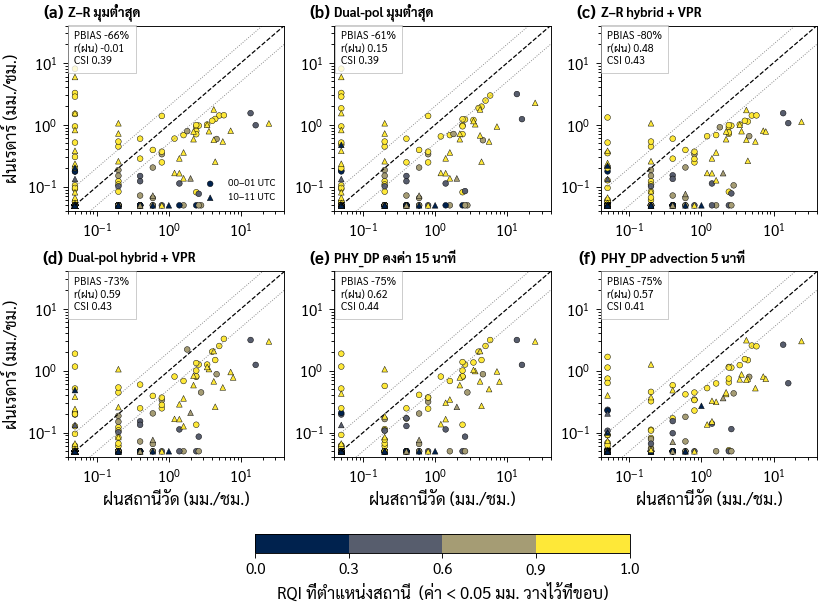

In [4]:
FLOOR, TOP = 0.05, 40
show_p = ["LS_MP", "LS_DP", "HYZ_MP", "PHY_DP", "SCAN_HOLD", "ADV_05"]
title = {"LS_MP": "Z–R มุมต่ำสุด", "LS_DP": "Dual-pol มุมต่ำสุด", "HYZ_MP": "Z–R hybrid + VPR",
         "PHY_DP": "Dual-pol hybrid + VPR", "SCAN_HOLD": "PHY_DP คงค่า 15 นาที", "ADV_05": "PHY_DP advection 5 นาที"}
rqi_of = {"LS_MP": "rqi_LS", "LS_DP": "rqi_LS", "HYZ_MP": "rqi_HYZ"}
cq, nq = pl.rqi_cmap((0, 0.3, 0.6, 0.9, 1.0))
fig, axs = pl.subplots(2, 3, width="double", height_mm=140)
for ax, p in zip(axs.ravel(), show_p):
    for h, mk in zip(sorted(pairs.start_utc.unique()), ["o", "^"]):
        s = pairs[pairs.start_utc == h]
        sc = ax.scatter(np.clip(s.G, FLOOR, None), np.clip(s[p], FLOOR, None), c=s[rqi_of.get(p, "rqi_PHY")], cmap=cq, norm=nq,
                        s=14, marker=mk, edgecolor="k", lw=0.3, label=f"{pd.Timestamp(h):%H}–{pd.Timestamp(h) + pd.Timedelta(hours=1):%H} UTC")
    pl.one_to_one(ax, FLOOR, TOP)
    ax.set_xscale("log"); ax.set_yscale("log"); ax.set_xlim(FLOOR * 0.8, TOP); ax.set_ylim(FLOOR * 0.8, TOP)
    m = verify.metrics(pairs.G, pairs[p])
    ax.text(0.03, 0.97, f"PBIAS {m['PBIAS']:.0f}%\nr(ฝน) {m.get('r_wet', np.nan):.2f}\nCSI {m['CSI']:.2f}", transform=ax.transAxes,
            va="top", fontsize=7, bbox=dict(fc="white", ec="0.6", lw=0.4, alpha=0.8))
    ax.set_title(title[p], loc="left", fontweight="bold", fontsize=8.5)
for ax in axs[1]: ax.set_xlabel(pl.L("gauge_mm"))
for ax in axs[:, 0]: ax.set_ylabel(pl.L("radar_mm"))
axs[0, 0].legend(loc="lower right", fontsize=6.5)
fig.colorbar(sc, ax=axs, orientation="horizontal", shrink=0.5).set_label("RQI ที่ตำแหน่งสถานี  (ค่า < 0.05 มม. วางไว้ที่ขอบ)")
pl.panel_labels(axs); pl.save(fig, "07_scatter_products"); plt.show()

## 4. แยกตามลุ่มน้ำ

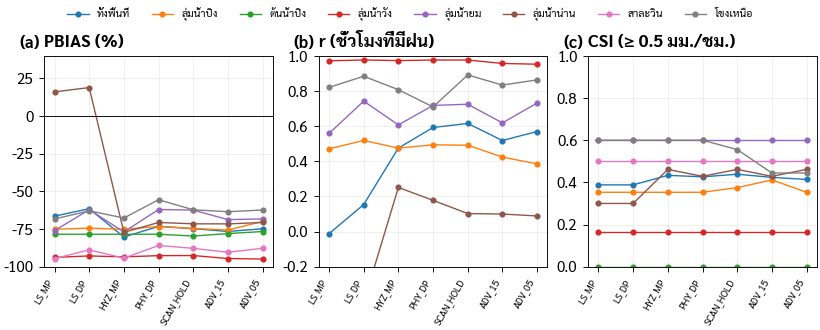

product,LS_MP,LS_DP,HYZ_MP,PHY_DP,SCAN_HOLD,ADV_15,ADV_05
group,,,,,,,
ทั้งพื้นที่,-66.0,-61.0,-80.0,-73.0,-75.0,-77.0,-75.0
ลุ่มน้ำปิง,-75.0,-74.0,-75.0,-73.0,-75.0,-76.0,-70.0
ต้นน้ำปิง,-78.0,-78.0,-78.0,-78.0,-80.0,-78.0,-77.0
ลุ่มน้ำวัง,-94.0,-93.0,-93.0,-93.0,-93.0,-95.0,-95.0
ลุ่มน้ำยม,-76.0,-62.0,-77.0,-62.0,-62.0,-69.0,-68.0
ลุ่มน้ำน่าน,16.0,19.0,-77.0,-71.0,-72.0,-72.0,-71.0
สาละวิน,-95.0,-89.0,-94.0,-86.0,-88.0,-90.0,-88.0
โขงเหนือ,-68.0,-63.0,-68.0,-56.0,-62.0,-63.0,-62.0


In [5]:
groups = {"ทั้งพื้นที่": pairs, "ลุ่มน้ำปิง": pairs[pairs.basin == "ปิง"], "ต้นน้ำปิง": pairs[pairs.headwater],
          "ลุ่มน้ำวัง": pairs[pairs.basin == "วัง"], "ลุ่มน้ำยม": pairs[pairs.basin == "ยม"], "ลุ่มน้ำน่าน": pairs[pairs.basin == "น่าน"],
          "สาละวิน": pairs[pairs.basin == "สาละวิน"], "โขงเหนือ": pairs[pairs.basin == "โขงเหนือ"]}
MB = pd.concat([verify.metrics_table(d, PRODUCTS).assign(group=k) for k, d in groups.items()])
MB.to_csv(P.tables / "07_metrics_by_basin.csv", index=False, encoding="utf-8-sig")
fig, axs = pl.subplots(1, 3, width="double", height_mm=70)
x = np.arange(len(PRODUCTS)); cols = plt.get_cmap("tab10")
for i, (k, d) in enumerate(MB.groupby("group", sort=False)):
    d = d.set_index("product").reindex(PRODUCTS)
    for ax, col_, lim in [(axs[0], "PBIAS", (-100, 40)), (axs[1], "r_wet", (-0.2, 1)), (axs[2], "CSI", (0, 1))]:
        ax.plot(x, d[col_], "-o", ms=3, lw=0.9, color=cols(i), label=k); ax.set_ylim(*lim)
for ax, t in zip(axs, ["PBIAS (%)", "r (ชั่วโมงที่มีฝน)", "CSI (≥ 0.5 มม./ชม.)"]):
    ax.set_xticks(x); ax.set_xticklabels(PRODUCTS, rotation=60, ha="right", fontsize=6.5); ax.set_title(t, loc="left", fontweight="bold"); ax.grid(alpha=0.3, lw=0.4)
axs[0].axhline(0, color="k", lw=0.6)
h_, l_ = axs[0].get_legend_handles_labels()
fig.legend(h_, l_, loc="upper center", ncol=8, bbox_to_anchor=(0.5, 1.10), fontsize=7)
pl.panel_labels(axs); pl.save(fig, "07_metrics_by_basin"); plt.show()
MB.pivot_table(index="group", columns="product", values="PBIAS", sort=False)[PRODUCTS].round(0)

## 5. แยกตามชั้นคุณภาพ RQI — RQI บอกความน่าเชื่อถือได้จริงหรือไม่

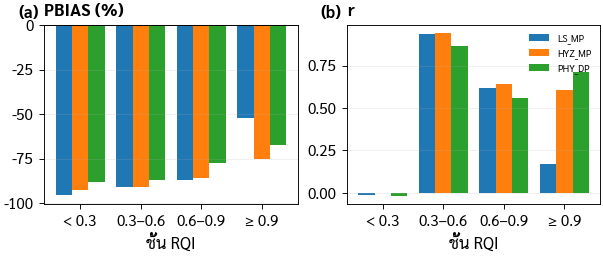

,product,RQI,n,G_mean,R_mean,PBIAS,r,RMSE
0,LS_MP,< 0.3,121,0.08,0.00,-95.59,-0.01,0.30
1,LS_MP,0.3–0.6,74,0.51,0.05,-90.93,0.94,2.27
2,LS_MP,0.6–0.9,58,0.37,0.05,-87.26,0.62,0.82
3,LS_MP,≥ 0.9,144,0.81,0.39,-52.32,0.17,2.47
4,HYZ_MP,< 0.3,128,0.05,0.00,-92.92,0.00,0.15
5,HYZ_MP,0.3–0.6,76,0.53,0.05,-91.14,0.94,2.25
6,HYZ_MP,0.6–0.9,60,0.36,0.05,-86.17,0.64,0.80
7,HYZ_MP,≥ 0.9,145,0.86,0.21,-75.15,0.61,2.35
8,PHY_DP,< 0.3,128,0.05,0.01,-88.09,-0.02,0.16
9,PHY_DP,0.3–0.6,76,0.53,0.07,-86.77,0.86,2.13


In [6]:
bins = [0, 0.3, 0.6, 0.9, 1.01]; labs = ["< 0.3", "0.3–0.6", "0.6–0.9", "≥ 0.9"]
rq = []
for p in ["LS_MP", "HYZ_MP", "PHY_DP"]:
    cls = pd.cut(pairs[rqi_of.get(p, "rqi_PHY")], bins, labels=labs, right=False)
    for c in labs:
        s = pairs[cls == c]; rq.append({"product": p, "RQI": c, **verify.metrics(s.G, s[p])})
RQ = pd.DataFrame(rq); RQ.to_csv(P.tables / "07_metrics_by_rqi.csv", index=False)
fig, axs = pl.subplots(1, 2, width="one_half", height_mm=60)
for i, p in enumerate(["LS_MP", "HYZ_MP", "PHY_DP"]):
    d = RQ[RQ["product"] == p]
    axs[0].bar(np.arange(4) + (i - 1) * 0.27, d.PBIAS, 0.27, label=p)
    axs[1].bar(np.arange(4) + (i - 1) * 0.27, d.r, 0.27, label=p)
for ax, t in zip(axs, ["PBIAS (%)", "r"]):
    ax.set_xticks(range(4)); ax.set_xticklabels(labs); ax.set_xlabel("ชั้น RQI"); ax.set_title(t, loc="left", fontweight="bold"); ax.grid(alpha=0.3, lw=0.4, axis="y")
axs[0].axhline(0, color="k", lw=0.6); axs[1].legend(fontsize=6.5)
pl.panel_labels(axs); pl.save(fig, "07_metrics_by_rqi"); plt.show()
RQ[["product", "RQI", "n", "G_mean", "R_mean", "PBIAS", "r", "RMSE"]].round(2)

## 6. แผนที่อัตราส่วนเรดาร์/สถานี

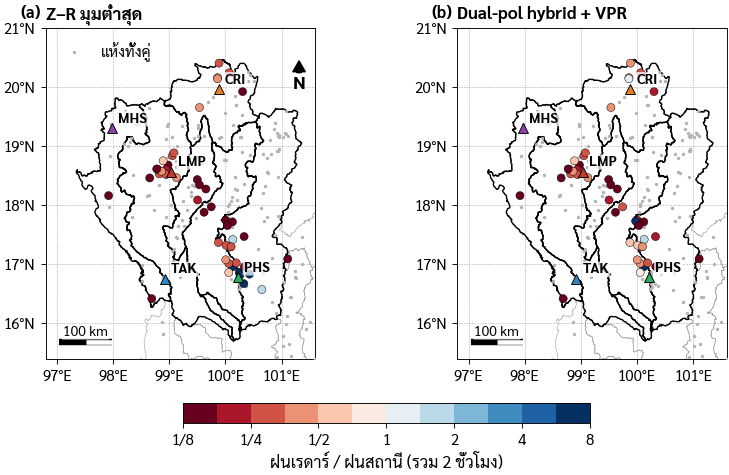

In [7]:
st = pairs.groupby("station_code").agg(lon=("lon", "first"), lat=("lat", "first"), G=("G", "sum"), LS_MP=("LS_MP", "sum"), PHY_DP=("PHY_DP", "sum"))
cr, nr = pl.ratio_cmap()
E = cfg["study_area"]["map_extent"]["north"]
fig, axs = pl.subplots(1, 2, width="double", height_mm=110)
for ax, p, t in [(axs[0], "LS_MP", "Z–R มุมต่ำสุด"), (axs[1], "PHY_DP", "Dual-pol hybrid + VPR")]:
    wet = (st.G >= 1) | (st[p] >= 1)
    ax.scatter(st.lon[~wet], st.lat[~wet], s=5, c="0.7", lw=0, zorder=12, label="แห้งทั้งคู่")
    sc = ax.scatter(st.lon[wet], st.lat[wet], c=np.log2((st[p][wet] + 0.2) / (st.G[wet] + 0.2)), cmap=cr, norm=nr, s=28, edgecolor="k", lw=0.3, zorder=13)
    mp.basemap(ax, E, title=t, scale_km=100, north=(p == "LS_MP"))
axs[0].legend(loc="upper left")
cb = fig.colorbar(sc, ax=axs, orientation="horizontal", shrink=0.5, ticks=[-3, -2, -1, 0, 1, 2, 3])
cb.ax.set_xticklabels(["1/8", "1/4", "1/2", "1", "2", "4", "8"]); cb.set_label("ฝนเรดาร์ / ฝนสถานี (รวม 2 ชั่วโมง)")
pl.panel_labels(axs); pl.save(fig, "07_bias_ratio_map"); plt.show()

## 7. แปลผล (อภิปรายในชั้นเรียน)
1. **เรดาร์ต่ำกว่าสถานีมากทุกวิธี** (ΣR/ΣG ≈ 0.2–0.4) แม้ที่ RQI ≥ 0.9 → ไม่ใช่แค่ปัญหาภูเขา แต่มี **bias ของการปรับเทียบ Z และ/หรือ Z–R** ร่วมด้วย
   → ขั้นการปรับแก้ด้วยฝนสถานี (notebook 08) จำเป็น
2. **มุมต่ำสุด (LS) ให้ PBIAS ดีที่สุดแต่ r ต่ำมาก** เพราะมี "ฝนปลอม" จาก clutter/AP รอบเรดาร์พิษณุโลก (สถานีแห้งแต่เรดาร์ 1–8 มม.)
   hybrid scan ตัดออกได้ — **ค่าเฉลี่ยดีไม่ได้แปลว่าผลิตภัณฑ์ดี** ต้องดูหลายดัชนีพร้อมกัน
3. **Dual-pol ดีกว่า Z–R** ทั้งแบบ LS และ hybrid (PBIAS ดีขึ้น 5–7 จุด, r_wet สูงขึ้น 0.1–0.15)
4. **RQI มีความหมายจริง**: ชั้น RQI ต่ำ bias รุนแรงและ r ≈ 0
5. **Advection ไม่ช่วยในระดับชั่วโมง-จุด** สำหรับ 2 ชั่วโมงนี้
6. **ข้อจำกัด**: 2 ชั่วโมง ฝนเบา คู่ที่มีฝน ~60 คู่ ถูกครอบงำโดยไม่กี่สถานี → ต้องขยายเป็นทั้งเหตุการณ์ก่อนสรุปลงงานวิจัย

---
## ✏️ แบบฝึกหัด

### แบบฝึกหัด 1 · 🟢 ป.ตรี

คำนวณ **PBIAS และ RMSE ของ PHY_DP ด้วยตนเอง** (ใช้ numpy) แล้วเทียบกับ `verify.metrics`

In [8]:
# ✏️ เขียนคำตอบของคุณในเซลล์นี้
pbias = None; rmse = None

In [9]:
#@title 🔑 เฉลยข้อ 1 — ลองทำเองก่อน แล้วดับเบิลคลิกเพื่อดูโค้ด { display-mode: "form" }
k = np.isfinite(pairs.G) & np.isfinite(pairs.PHY_DP)
G_, R_ = pairs.G[k].values, pairs.PHY_DP[k].values
pbias = 100 * (R_ - G_).sum() / G_.sum(); rmse = np.sqrt(np.mean((R_ - G_) ** 2))
m = verify.metrics(pairs.G, pairs.PHY_DP)
print(f"PBIAS {pbias:.2f}% (ฟังก์ชัน {m['PBIAS']:.2f}%),  RMSE {rmse:.3f} มม. (ฟังก์ชัน {m['RMSE']:.3f})")
assert abs(pbias - m["PBIAS"]) < 1e-9

PBIAS -73.21% (ฟังก์ชัน -73.21%),  RMSE 1.615 มม. (ฟังก์ชัน 1.615)


### แบบฝึกหัด 2 · 🟢 ป.ตรี

สร้าง **ตาราง contingency ที่เกณฑ์ 1 มม./ชม.** สำหรับ LS_MP และ PHY_DP แล้วคำนวณ POD, FAR, CSI ผลิตภัณฑ์ใดมี false alarm มากกว่า เพราะอะไร

In [10]:
# ✏️ เขียนคำตอบของคุณในเซลล์นี้
ct = None

In [11]:
#@title 🔑 เฉลยข้อ 2 — ลองทำเองก่อน แล้วดับเบิลคลิกเพื่อดูโค้ด { display-mode: "form" }
ct = {}
for p in ["LS_MP", "PHY_DP"]:
    k = np.isfinite(pairs.G) & np.isfinite(pairs[p]); G_, R_ = pairs.G[k], pairs[p][k]
    a = int(((G_ >= 1) & (R_ >= 1)).sum()); b = int(((G_ < 1) & (R_ >= 1)).sum()); c = int(((G_ >= 1) & (R_ < 1)).sum())
    ct[p] = dict(hits=a, false_alarms=b, misses=c, POD=a / (a + c), FAR=b / max(a + b, 1), CSI=a / (a + b + c))
display(pd.DataFrame(ct).T.round(2))
print("LS_MP มี false alarm มากกว่า (clutter/AP ใกล้ PHS ที่มุม 0.48°)")

,hits,false_alarms,misses,POD,FAR,CSI
LS_MP,8.0,8.0,33.0,0.20,0.50,0.16
PHY_DP,15.0,3.0,27.0,0.36,0.17,0.33


LS_MP มี false alarm มากกว่า (clutter/AP ใกล้ PHS ที่มุม 0.48°)


### แบบฝึกหัด 3 · 🟢 ป.ตรี

เรียงลำดับผลิตภัณฑ์ตาม **KGE** และตาม **r_wet** ลำดับเหมือนกันหรือไม่ ถ้าต้องเลือก 1 ผลิตภัณฑ์ไปใช้เตือนภัยน้ำท่วม จะเลือกอะไร เพราะอะไร

In [12]:
# ✏️ เขียนคำตอบของคุณในเซลล์นี้
rank = None

In [13]:
#@title 🔑 เฉลยข้อ 3 — ลองทำเองก่อน แล้วดับเบิลคลิกเพื่อดูโค้ด { display-mode: "form" }
rank = M.set_index("product")[["KGE", "r_wet", "PBIAS", "CSI"]].sort_values("KGE", ascending=False).round(2)
display(rank)
print("KGE ลงโทษ bias หนัก ส่วน r_wet ดูรูปแบบ — สำหรับเตือนภัย รูปแบบเชิงพื้นที่ (r, CSI) สำคัญ และแก้ bias ได้ด้วยสถานี (nb 08) → PHY_DP")

,KGE,r_wet,PBIAS,CSI
product,,,,
LS_DP,-0.08,0.15,-61.47,0.39
PHY_DP,-0.10,0.59,-73.21,0.43
SCAN_HOLD,-0.11,0.62,-74.73,0.44
ADV_05,-0.13,0.57,-74.82,0.41
ADV_15,-0.16,0.52,-76.63,0.42
LS_MP,-0.20,-0.01,-66.45,0.39
HYZ_MP,-0.22,0.48,-80.33,0.43


KGE ลงโทษ bias หนัก ส่วน r_wet ดูรูปแบบ — สำหรับเตือนภัย รูปแบบเชิงพื้นที่ (r, CSI) สำคัญ และแก้ bias ได้ด้วยสถานี (nb 08) → PHY_DP


### แบบฝึกหัด 4 · 🔵 ป.โท / ส่วนขยาย

ประเมิน **ความไม่แน่นอน** ของผลต่าง PBIAS ระหว่าง PHY_DP กับ LS_MP ด้วย bootstrap (สุ่มสถานีแบบใส่คืน 1,000 ครั้ง) ช่วงความเชื่อมั่น 95% ครอบคลุม 0 หรือไม่ หมายความว่าอะไร

In [14]:
# ✏️ เขียนคำตอบของคุณในเซลล์นี้
ci = None

In [15]:
#@title 🔑 เฉลยข้อ 4 — ลองทำเองก่อน แล้วดับเบิลคลิกเพื่อดูโค้ด { display-mode: "form" }
rng = np.random.default_rng(42); codes = pairs.station_code.unique(); diffs = []
by = {c: d for c, d in pairs.groupby("station_code")}
for _ in range(1000):
    s = pd.concat([by[c] for c in rng.choice(codes, len(codes))])
    diffs.append(verify.metrics(s.G, s.PHY_DP)["PBIAS"] - verify.metrics(s.G, s.LS_MP)["PBIAS"])
ci = np.nanpercentile(diffs, [2.5, 97.5])
print(f"ΔPBIAS (PHY − LS) 95% CI = [{ci[0]:.1f}, {ci[1]:.1f}] จุดร้อยละ")
print("ถ้าครอบคลุม 0 แปลว่าตัวอย่างน้อยเกินกว่าจะสรุปว่าวิธีหนึ่งดีกว่าอีกวิธีในด้าน bias")

ΔPBIAS (PHY − LS) 95% CI = [-30.8, 6.0] จุดร้อยละ
ถ้าครอบคลุม 0 แปลว่าตัวอย่างน้อยเกินกว่าจะสรุปว่าวิธีหนึ่งดีกว่าอีกวิธีในด้าน bias


### แบบฝึกหัด 5 · 🔵 ป.โท / ส่วนขยาย

ทดสอบความไวต่อ **ขนาดหน้าต่างการสุ่ม** (1×1, 3×3, 5×5) สำหรับ PHY_DP ดัชนีใดเปลี่ยนมากที่สุด เพราะอะไร

In [16]:
# ✏️ เขียนคำตอบของคุณในเซลล์นี้
sens = None

In [17]:
#@title 🔑 เฉลยข้อ 5 — ลองทำเองก่อน แล้วดับเบิลคลิกเพื่อดูโค้ด { display-mode: "form" }
res = []
for w in [1, 3, 5]:
    rr = []
    for tag, t0 in [("00UTC", "2024-10-03 00:00"), ("10UTC", "2024-10-03 10:00")]:
        mo = np.load(P.products / f"mosaic_20241003_{tag}.npz"); s = pairs[pairs.start_utc == t0]
        rr.append(pd.DataFrame({"G": s.G.values, "R": verify.sample(mo["h_PHY_DP"], mo["glon"], mo["glat"], s.lon, s.lat, w)}))
    d = pd.concat(rr); res.append({"window": f"{w}x{w}", **verify.metrics(d.G, d.R)})
sens = pd.DataFrame(res).set_index("window")[["PBIAS", "RMSE", "r", "r_wet", "POD", "FAR", "CSI"]].round(2)
display(sens)
print("หน้าต่างใหญ่ขึ้น: PBIAS ติดลบน้อยลง (ดึงฝนจากพิกเซลรอบ ๆ เข้ามา) แต่ r ลดลงเพราะค่าถูกเกลี่ย และ FAR เพิ่มเพราะฝนข้างเคียง 'ไหล' เข้าจุดที่แห้ง")
print("→ ไม่มีขนาดหน้าต่างที่ถูกเสมอ ต้องรายงานว่าใช้ขนาดใดและทดสอบความไว")

,PBIAS,RMSE,r,r_wet,POD,FAR,CSI
window,,,,,,,
1x1,-75.22,1.62,0.75,0.61,0.51,0.10,0.48
3x3,-73.21,1.61,0.73,0.59,0.47,0.19,0.43
5x5,-68.53,1.60,0.68,0.51,0.51,0.22,0.44


หน้าต่างใหญ่ขึ้น: PBIAS ติดลบน้อยลง (ดึงฝนจากพิกเซลรอบ ๆ เข้ามา) แต่ r ลดลงเพราะค่าถูกเกลี่ย และ FAR เพิ่มเพราะฝนข้างเคียง 'ไหล' เข้าจุดที่แห้ง
→ ไม่มีขนาดหน้าต่างที่ถูกเสมอ ต้องรายงานว่าใช้ขนาดใดและทดสอบความไว


---
## 💡 คำถามชวนคิดและต่อยอด
- ถ้าประเมินด้วยฝนสะสมทั้งเหตุการณ์ (เช่น 72 ชั่วโมง) แทนรายชั่วโมง ดัชนีจะเปลี่ยนอย่างไร และเหมาะกับคำถามแบบไหน
- ควรรายงานผลแยกตามความสูงภูมิประเทศของสถานี (ที่ราบ/เชิงเขา/ภูเขา) หรือไม่ เกี่ยวกับ "ฝนบนภูเขา" อย่างไร
- การตรวจสอบนี้ใช้สถานีทั้งหมด แต่ถ้าใช้สถานีไปปรับแก้เรดาร์แล้ว จะตรวจสอบอย่างไรให้ "ยุติธรรม" (notebook 08: cross-validation)
- 🔵 ลองดัชนีเชิงพื้นที่ เช่น Fractions Skill Score (FSS) ที่ไม่ลงโทษการเลื่อนตำแหน่งเล็กน้อย

## 📚 อ้างอิง
- Gupta, H.V. et al. (2009). Decomposition of the mean squared error and NSE performance criteria. *J. Hydrol.* 377:80–91.
- Wilks, D.S. (2019). *Statistical Methods in the Atmospheric Sciences*, 4th ed., ch. 9. Elsevier.
- Ciach, G.J. & Krajewski, W.F. (1999). On the estimation of radar rainfall error variance. *Adv. Water Resour.* 22:585–595.
- Roberts, N.M. & Lean, H.W. (2008). Scale-selective verification of rainfall accumulations. *Mon. Wea. Rev.* 136:78–97.

In [18]:
#@title 💾 บันทึกผลลัพธ์ขึ้น GitHub (fork ของคุณเอง) { display-mode: "form" }
#@markdown ใส่รหัสนิสิต แล้วรันเซลล์นี้ (ต้องตั้ง Colab Secrets `GITHUB_USER` และ `GITHUB_TOKEN` ก่อน — ดูขั้นตอนใน notebook 00)
STUDENT_ID = ""  #@param {type:"string"}
if STUDENT_ID:
    colab.save_to_fork(STUDENT_ID, message="NB07: results")
else:
    print("ยังไม่ได้ใส่รหัสนิสิต — ข้ามการบันทึก (ผลยังอยู่ในโฟลเดอร์ outputs/ ของ Colab)")

ยังไม่ได้ใส่รหัสนิสิต — ข้ามการบันทึก (ผลยังอยู่ในโฟลเดอร์ outputs/ ของ Colab)
